# Part 2 baseline (non-leading partner): Zoheb Waghu

DATA 266 Lab 2, Pair_Programming_Team_32. The brief asks the partner who did not lead Part 2 to run the complete
pipeline at least as a working baseline. This notebook runs the team's Part 2 code (`part2_diffusion/src/`, tag
`p2-v1.0`) end to end on one Colab T4, with a smaller budget than the final runs:

| | This baseline | Final runs (`p2_finetune.ipynb`) |
|---|---|---|
| LoRA rank | 4 | 4 and 32 |
| Training steps | 500 | 1500 |
| Batch size, learning rate, target modules | same (4, 1e-4, to_q/to_k/to_v/to_out.0) | |
| Data | same cleaning and 90/10 split, seed 266 | |
| Prompts and sampler | same 20 prompts, seeds 0 and 1, DPM-Solver++ 30 steps, guidance 7.5 | |
| Metrics | KID, CLIP score, LPIPS | + memorization, human evaluation |

**How to run:** Runtime → Change runtime type → **T4 GPU**. Add a Colab secret `GITHUB_TOKEN` (key icon on the left)
with a GitHub token that can read `sakotiya/data266-lab2-team32`. Then Runtime → **Run all**. About 35–45 minutes.
Results are saved to Google Drive (`MyDrive/data266_p2_baseline_zoheb`), so a disconnect does not lose finished work;
rerunning skips finished training.

In [3]:
# Cell 1 - run information
import os, subprocess, sys, datetime, platform
REPO = "sakotiya/data266-lab2-team32"
REF = "p2-v1.0"                      # the tagged Part 2 code
WORK = "/content/data266-lab2-team32"

from google.colab import drive, userdata
drive.mount("/content/drive")
if not os.path.isdir(WORK):
    token = userdata.get("GITHUB_TOKEN")
    subprocess.run(["git", "clone", "-q", f"https://{token}@github.com/{REPO}.git", WORK], check=True)
    subprocess.run(["git", "-C", WORK, "checkout", "-q", REF], check=True)
os.chdir(WORK); sys.path.insert(0, WORK)

commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()
gpu = subprocess.run(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"], capture_output=True, text=True).stdout.strip()
print("run by: Zoheb Waghu (Part 2 baseline, non-leading partner)")
print("date:", datetime.datetime.now().isoformat(timespec="minutes"))
print("code:", REPO, REF, "commit", commit)
print("python:", platform.python_version(), "| GPU:", gpu or "NONE - switch the runtime to T4")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
run by: Zoheb Waghu (Part 2 baseline, non-leading partner)
date: 2026-11-15T22:28
code: sakotiya/data266-lab2-team32 p2-v1.0 commit 285e5f3
python: 3.13.16 | GPU: Tesla T4


In [4]:
!pip install -q diffusers==0.42.1 transformers==5.22.1 peft==0.21.2 datasets==4.8.5 torchmetrics==1.9.0 lpips==0.1.4 torch-fidelity==0.3.0

from importlib.metadata import version
for pkg in ["torch", "diffusers", "transformers", "peft", "datasets", "torchmetrics", "lpips", "torch-fidelity"]:
    print(f"{pkg}=={version(pkg)}")

torch==2.14.1+cu130
diffusers==0.42.1
transformers==5.22.1
peft==0.21.2
datasets==4.8.5
torchmetrics==1.9.0
lpips==0.1.4
torch-fidelity==0.3.0


In [5]:
# Results go to Drive; data and big files (weights, images) too, so a disconnect loses nothing.
RESULTS = "/content/drive/MyDrive/data266_p2_baseline_zoheb"
os.environ.update(P2_DATA="/content/data", P2_RESULTS=RESULTS, P2_BIG=f"{RESULTS}/big")

import random, numpy as np, torch
SEED = 266; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# Use the team code with one baseline run (rank 4, 500 steps) instead of the two final runs.
from part2_diffusion.src import common
RUN = "baseline_zoheb_r4"
STEPS = 500
common.CONFIG["runs"] = {RUN: {"rank": 4}}
common.RUNS = [RUN]
common.MODELS = ["base", RUN]
print("models compared:", common.MODELS, "| results:", RESULTS)

models compared: ['base', 'baseline_zoheb_r4'] | results: /content/drive/MyDrive/data266_p2_baseline_zoheb


## 2.1 Data preparation
Same cleaning (corrupted, exact and near duplicates) and the same 90/10 split with seed 266.

In [6]:
import json
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from part2_diffusion.src import data

summary = data.prepare()
print(json.dumps(summary, indent=2))

README.md:   0%|          | 0.00/1.02k [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


dataset_infos.json:   0%|          | 0.00/897 [00:00<?, ?B/s]

data/train-00000-of-00002-12944970063701(…): reconstructing file:   0%|          |  0.00B /  344MB            

data/train-00000-of-00002-12944970063701(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-cefa2f480689f1(…): reconstructing file:   0%|          |  0.00B /  357MB            

data/train-00001-of-00002-cefa2f480689f1(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1221 [00:00<?, ? examples/s]

loaded 1221 images
removed 0 {}
smallest dHash distance between kept images: 5
{
  "dataset": "lambdalabs/naruto-blip-captions",
  "rows_loaded": 1221,
  "removed": 0,
  "removed_by_reason": {},
  "kept": 1221,
  "train": 1099,
  "test": 122,
  "seed": 266,
  "closest_kept_dhash_distance": 5,
  "original_sizes_top5": {
    "1080x1080": 468,
    "1076x1076": 135,
    "1620x1620": 33,
    "1050x1050": 30,
    "540x540": 23
  },
  "caption_words_mean": 8.9,
  "top_caption_words": {
    "man": 692,
    "hair": 464,
    "white": 192,
    "shirt": 192,
    "eyes": 181,
    "long": 181,
    "black": 180,
    "woman": 175,
    "his": 163,
    "green": 142,
    "blue": 137,
    "hat": 126,
    "red": 115,
    "brown": 95,
    "sword": 86
  }
}


In [10]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


## 2.2 Fine-tuning (baseline)

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


baseline_zoheb_r4: rank 4, trainable parameters 797,184 (0.09% of the UNet)
step 20/500  loss 0.0787  0.7 min, about 16 min left
step 100/500  loss 0.0905  2.9 min, about 12 min left
step 200/500  loss 0.0925  5.8 min, about 9 min left
step 300/500  loss 0.0872  8.6 min, about 6 min left
step 400/500  loss 0.1026  11.5 min, about 3 min left
step 500/500  loss 0.0888  14.3 min, about 0 min left


,0
rank,4
trainable_params,797184
learning_rate,0.0001
steps,500
batch_size,4
peak_gpu_memory_gb,5.57
training_minutes,14.3
gpu_hours,0.238
gpu,Tesla T4


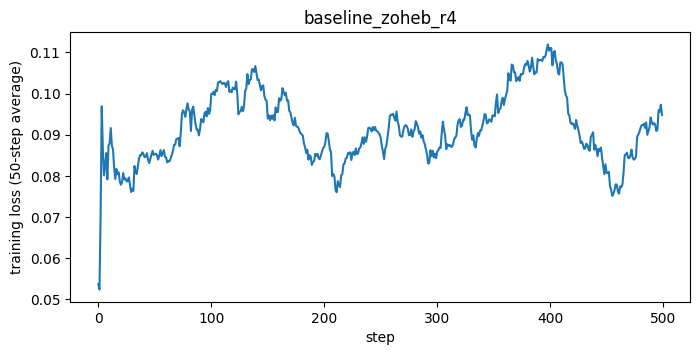

In [11]:
from part2_diffusion.src import train
stats = train.train(RUN, max_steps=STEPS)
show = ["rank", "trainable_params", "learning_rate", "steps", "batch_size",
        "peak_gpu_memory_gb", "training_minutes", "gpu_hours", "gpu"]
display(pd.Series({k: stats[k] for k in show}))

plt.figure(figsize=(8, 3.5))
plt.plot(pd.Series(stats["losses"]).rolling(50, min_periods=1).mean())
plt.xlabel("step"); plt.ylabel("training loss (50-step average)"); plt.title(RUN)
plt.savefig(common.OUTPUTS / "loss_curve_baseline.png", dpi=120, bbox_inches="tight")
plt.show()

## 2.3 Image generation
20 prompts × seeds 0 and 1, for the base model and the baseline LoRA. Safety checker on.

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

base done


No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


baseline_zoheb_r4 done
80 images, 1 flagged by the NSFW filter


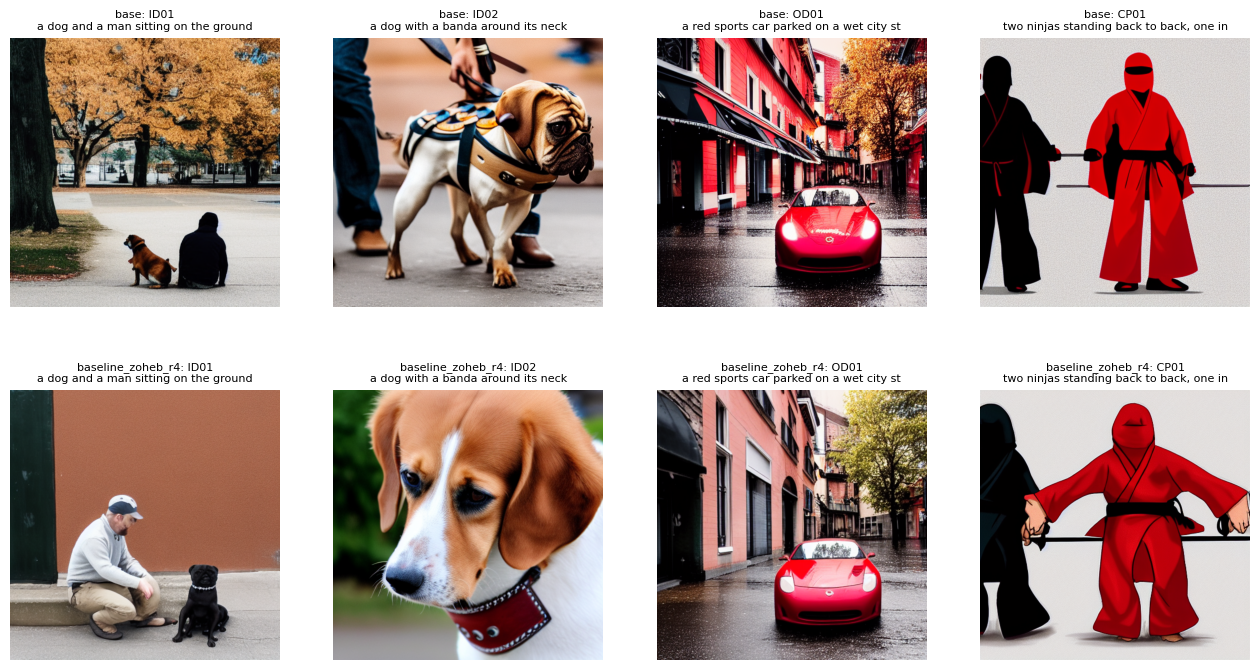

In [12]:
from part2_diffusion.src import generate
prompts = common.load_prompts()
gens = generate.generate(prompts)
print(len(gens), "images,", int(gens["nsfw_flagged"].sum()), "flagged by the NSFW filter")

ids = ["ID01", "ID02", "OD01", "CP01"]
fig, axes = plt.subplots(2, 4, figsize=(16, 8.4))
text = {p["prompt_id"]: p["prompt"] for p in prompts}
for col, pid in enumerate(ids):
    for row, model in enumerate(common.MODELS):
        axes[row, col].imshow(Image.open(common.image_path(model, pid, 0)))
        axes[row, col].set_title(f"{model}: {pid}\n{text[pid][:40]}", fontsize=8)
        axes[row, col].axis("off")
fig.savefig(common.OUTPUTS / "grid_baseline.jpg", dpi=80, bbox_inches="tight")
plt.show()

## 2.4 Evaluation
KID (in-domain generations vs test images) and CLIP score; LPIPS between the two seeds.

In [13]:
from part2_diffusion.src import evaluate
metrics, clip, clip_df = evaluate.evaluate(prompts)
metrics["gpu_hours"] = [None, stats["gpu_hours"]]
metrics["training_steps"] = [None, stats["steps"]]
metrics.to_csv(common.METRICS / "results_table_baseline.csv")
display(metrics.round(4))
display(clip_df.groupby(["model", "category"])["clip_score"].mean().unstack().round(2))

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (10 outputs left out)

Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth


/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)
Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:02<00:00, 38.7MB/s]


,kid_mean,kid_std,clip_score,clip_in_domain,lpips_between_seeds,gpu_hours,training_steps
base,0.1243,0.0181,31.8782,30.4415,0.8061,NaN,NaN
baseline_zoheb_r4,0.0702,0.0230,30.7078,29.5278,0.8230,0.238,500.0


category,compositional,in_domain,out_of_domain
model,,,
base,34.91,30.44,31.72
baseline_zoheb_r4,32.39,29.53,31.38


## Save to the repository

1. When every cell above has finished: File → **Download → Download .ipynb**.
2. In the Colab file panel (folder icon), upload that file to `/content/` as `p2_baseline_zoheb.ipynb`.
3. Fill in `GIT_EMAIL` below and run this cell. It copies the small result files (metrics, loss curve, grid; no weights
   or images) into `part2_diffusion/baseline_zoheb/`, adds the executed notebook, and pushes both to the branch
   `zoheb-p2-baseline` from your account.